In [125]:
from select import KQ_EV_ENABLE

# Import potrebnih biblioteka
import pandas as pd
import numpy as np
from matplotlib.pyplot import grid
from numpy.ma.extras import column_stack
from scipy.stats import shapiro, alpha
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score,precision_score,recall_score,f1_score
from statsmodels.sandbox.regression.ols_anova_original import dropn


FileNotFoundError: dftest3.data not found.

In [24]:
data = pd.read_csv('./data/spotify.csv',na_values=['-',' ',''],encoding='latin1')
display(data.head())
print(data.info())
print(data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            953 non-null    str    
 1   released_year         953 non-null    int64  
 2   in_spotify_playlists  953 non-null    int64  
 3   in_spotify_charts     951 non-null    float64
 4   streams               953 non-null    int64  
 5   in_apple_playlists    953 non-null    int64  
 6   in_apple_charts       951 non-null    float64
 7   bpm                   953 non-null    int64  
 8   mode                  953 non-null    str    
 9   energy                953 non-null    int64  
 10  instrumentalness      953 non-null    int64  
 11  liveness              953 non-null    int64  
 12  speechiness           953 non-null    int64  
dtypes: float64(2), int64(9), str(2)
memory usage: 96.9 KB
None
       released_year  in_spotify_playlists  in_spotify_charts       streams  

In [3]:
print(data.isna().sum())

track_name              0
released_year           0
in_spotify_playlists    0
in_spotify_charts       1
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
dtype: int64


In [25]:
streams_Q3 = data['streams'].quantile(0.75)
print(streams_Q3)
data['HighStreams']=np.where(data['streams']>streams_Q3,'Yes','No')
data['HighStreams']=data['HighStreams'].map({'Yes':1,'No':0})
data.drop(columns=['streams'],inplace=True)

673801126.0


In [6]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            953 non-null    str    
 1   released_year         953 non-null    int64  
 2   in_spotify_playlists  953 non-null    int64  
 3   in_spotify_charts     952 non-null    str    
 4   in_apple_playlists    953 non-null    int64  
 5   in_apple_charts       951 non-null    float64
 6   bpm                   953 non-null    int64  
 7   mode                  953 non-null    str    
 8   energy                953 non-null    int64  
 9   instrumentalness      953 non-null    int64  
 10  liveness              953 non-null    int64  
 11  speechiness           953 non-null    int64  
 12  HighStreams           953 non-null    int64  
dtypes: float64(1), int64(9), str(3)
memory usage: 96.9 KB
None


In [26]:
data.drop(columns=['track_name'],inplace=True)

In [9]:
print(data.info())
print(data.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     952 non-null    str    
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       951 non-null    float64
 5   bpm                   953 non-null    int64  
 6   mode                  953 non-null    str    
 7   energy                953 non-null    int64  
 8   instrumentalness      953 non-null    int64  
 9   liveness              953 non-null    int64  
 10  speechiness           953 non-null    int64  
 11  HighStreams           953 non-null    int64  
dtypes: float64(1), int64(9), str(2)
memory usage: 89.5 KB
None
released_year           0
in_spotify_playlists    0
in_spotify_charts       1
in_apple_playlists      0
in_apple_charts         

In [28]:
p_spotify = shapiro(data['in_spotify_charts'].dropna())[1]
p_apple = shapiro(data['in_apple_charts'].dropna())[1]

print("p-vrednost za in_spotify_charts:", p_spotify)
print("p-vrednost za in_apple_charts:", p_apple)

m_s = data['in_spotify_charts'].median()
m_a = data['in_apple_charts'].median()
print("median:", m_s)
print("median:", m_a)

data['in_spotify_charts'] = data['in_spotify_charts'].fillna(m_s)
data['in_apple_charts'] = data['in_apple_charts'].fillna(m_a)

p-vrednost za in_spotify_charts: 1.4519411043896683e-39
p-vrednost za in_apple_charts: 4.467185022285124e-26
median: 3.0
median: 38.0


In [30]:
print(data.isna().sum())

released_year           0
in_spotify_playlists    0
in_spotify_charts       0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
HighStreams             0
dtype: int64


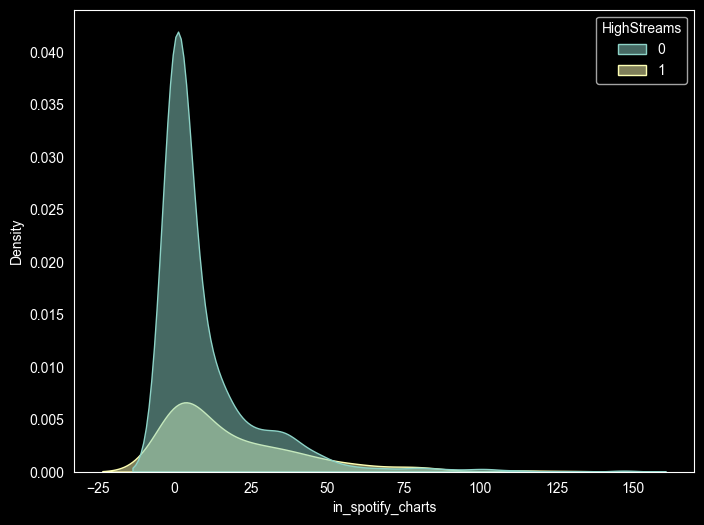

In [37]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='in_spotify_charts', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()


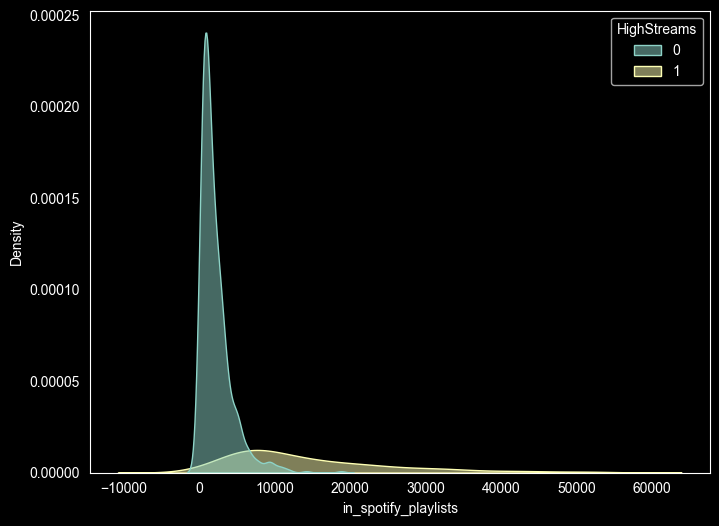

In [39]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='in_spotify_playlists', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

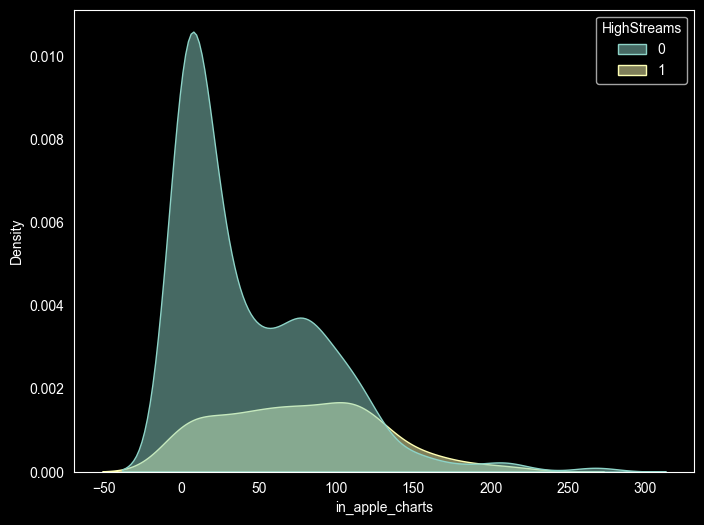

In [40]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='in_apple_charts', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

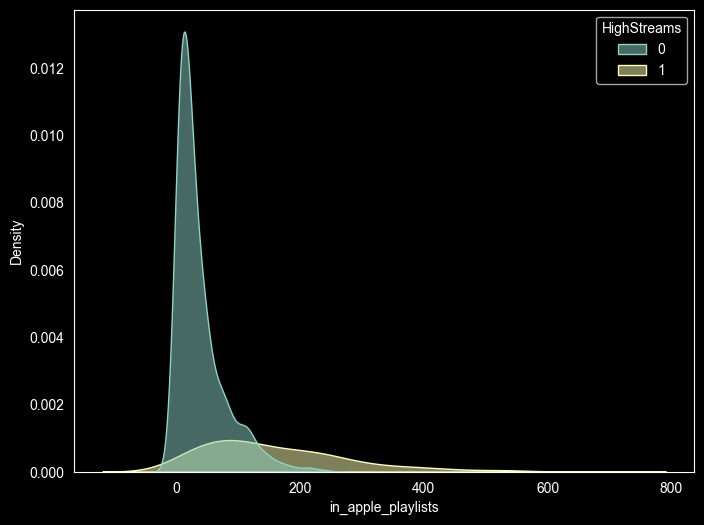

In [41]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='in_apple_playlists', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

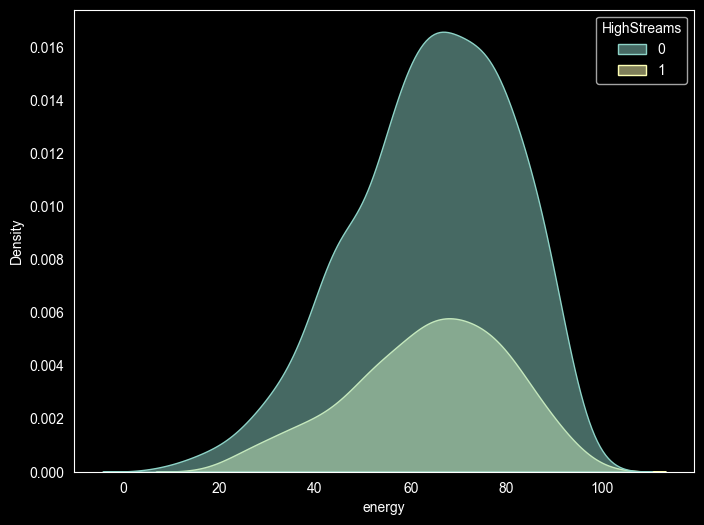

In [54]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='energy', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

data.drop(columns='energy',inplace=True)


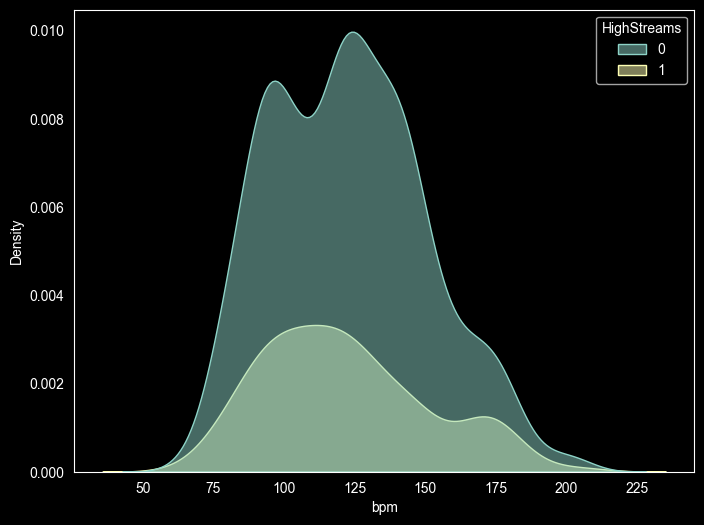

In [53]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='bpm', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

data.drop(columns='bpm',inplace=True)


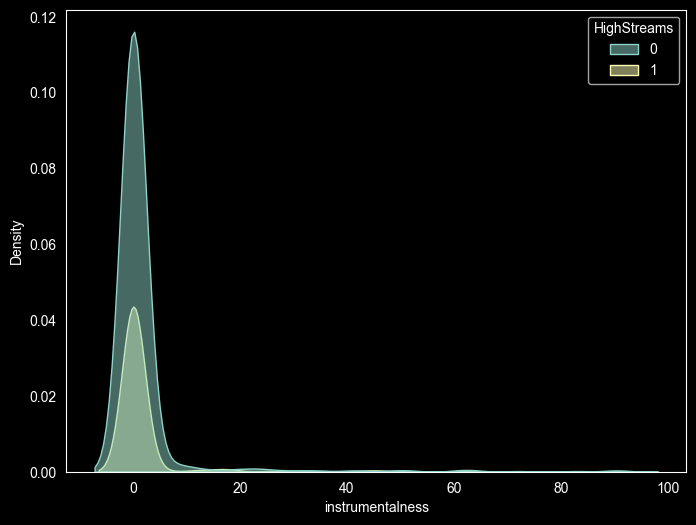

In [52]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='instrumentalness', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

data.drop(columns='instrumentalness',inplace=True)


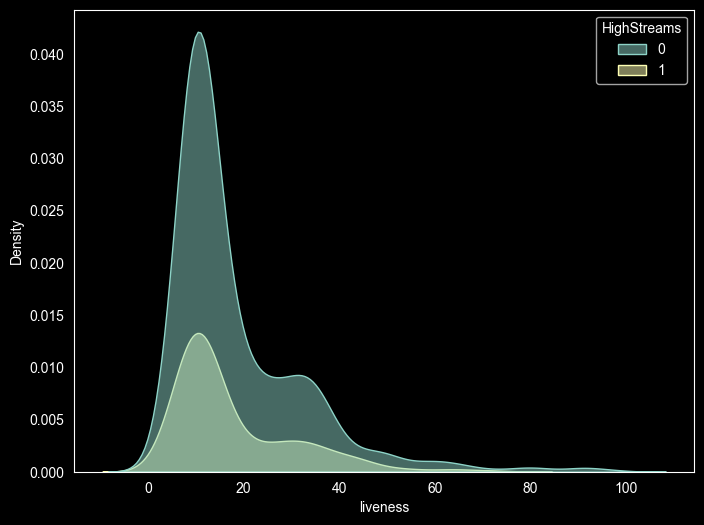

In [51]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='liveness', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

data.drop(columns='liveness',inplace=True)


In [ ]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='loudness', hue='HighStreams', fill=True ,alpha=0.55)
plt.grid()
plt.show()

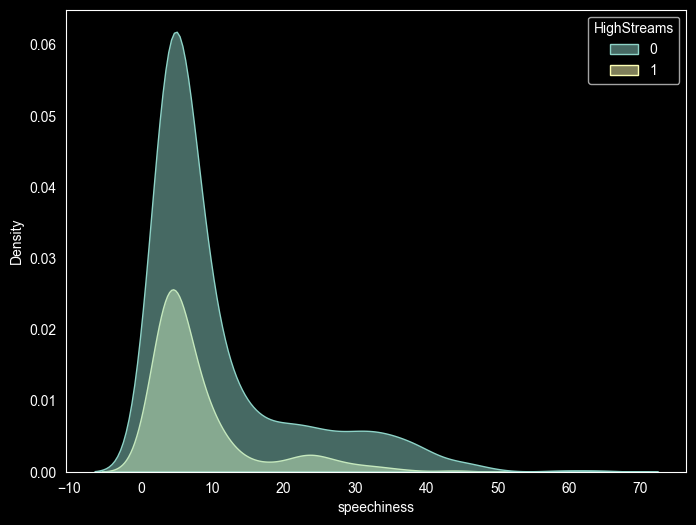

In [50]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='speechiness', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

data.drop(columns='speechiness',inplace=True)

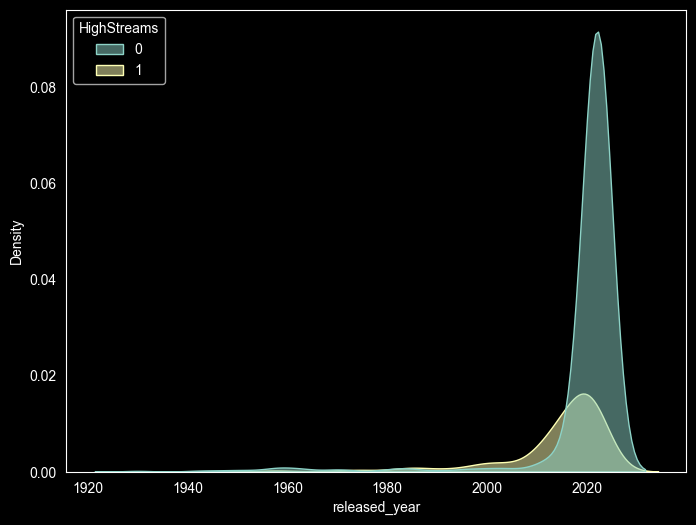

In [49]:
plt.figure(figsize=(8,6))
sns.kdeplot(data=data, x='released_year', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

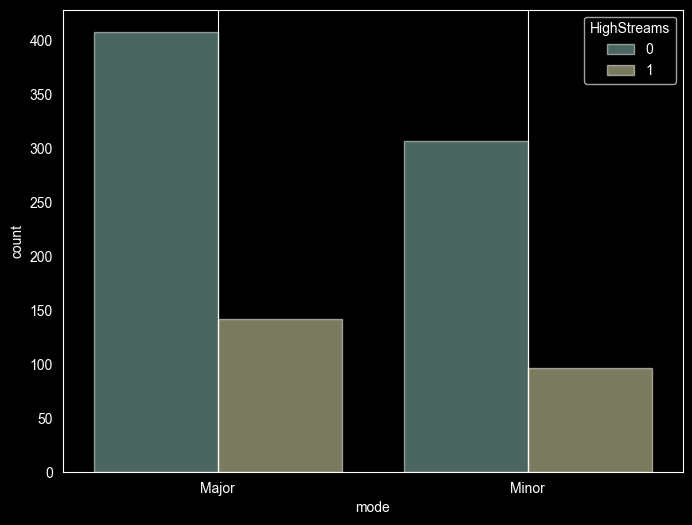

In [48]:
plt.figure(figsize=(8,6))
sns.countplot(data=data, x='mode', hue='HighStreams', fill=True ,alpha=0.5)
plt.grid()
plt.show()

In [55]:
print(data.info())
print(data.describe())
print(data.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     953 non-null    float64
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       953 non-null    float64
 5   mode                  953 non-null    str    
 6   HighStreams           953 non-null    int64  
dtypes: float64(2), int64(4), str(1)
memory usage: 52.2 KB
None
       released_year  in_spotify_playlists  in_spotify_charts  \
count     953.000000            953.000000         953.000000   
mean     2018.238195           5200.124869          11.853095   
std        11.116218           7897.608990          19.320751   
min      1930.000000             31.000000           0.000000   
25%      2020.000000            875.000000           0.0000

In [56]:
data.drop(columns='mode',inplace=True)


In [57]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     953 non-null    float64
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       953 non-null    float64
 5   HighStreams           953 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 44.8 KB
None


In [88]:
numeric_vars = ['released_year', 'in_spotify_playlists', 'in_spotify_charts', 'in_apple_playlists', 'in_apple_charts']

In [98]:
def out_(variable):
    q1 = variable.quantile(0.25)
    q3 = variable.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    upp = q3 + 1.5 * iqr
    return ((variable < low) | (variable>upp)).sum()

out_col = data[numeric_vars].apply(out_)
print(out_col)

released_year           151
in_spotify_playlists    109
in_spotify_charts        76
in_apple_playlists       78
in_apple_charts          12
dtype: int64


In [ ]:
def outliers(var):
    q1= var.quantile(0.25)
    q3= var.quantile(0.75)
    iqr = q3-q1
    lower= q1-1.5*iqr
    upper= q3+1.5*iqr
    return (var<lower)|(var>upper).sum()
out_col = data[numeric_vars].apply(outliers)
print(out_col)

In [90]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     953 non-null    float64
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       953 non-null    float64
 5   HighStreams           953 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 44.8 KB
None


In [99]:
shapiro_res = data[numeric_vars].apply( lambda x: shapiro(x)[1])

print(shapiro_res)

released_year           1.210310e-47
in_spotify_playlists    2.585440e-41
in_spotify_charts       1.284461e-39
in_apple_playlists      4.262281e-37
in_apple_charts         4.332586e-26
dtype: float64


In [ ]:
r_s = RobustScaler() #napravi se scaler
new_d = pd.DataFrame() #napravi se novi df
new_d[numeric_vars] = r_s.fit_transform(data[numeric_vars]) # normalizovane vrednosti se upisu u novi df

In [ ]:
new = pd.dataFrame()
new[numeric_vars] = RobustScaler().fit_transform(data[numeric_vars])

In [103]:
robust_scaler = RobustScaler()
ds = pd.DataFrame()
ds[numeric_vars] = robust_scaler.fit_transform(data[numeric_vars])


In [84]:
print(data.info())
print(data.describe())

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         953 non-null    int64  
 1   in_spotify_playlists  953 non-null    int64  
 2   in_spotify_charts     953 non-null    float64
 3   in_apple_playlists    953 non-null    int64  
 4   in_apple_charts       953 non-null    float64
 5   HighStreams           953 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 44.8 KB
None
       released_year  in_spotify_playlists  in_spotify_charts  \
count     953.000000            953.000000         953.000000   
mean     2018.238195           5200.124869          11.853095   
std        11.116218           7897.608990          19.320751   
min      1930.000000             31.000000           0.000000   
25%      2020.000000            875.000000           0.000000   
50%      2022.000000           2224.000000           

In [104]:
ds['HighStreams'] = data['HighStreams']

In [105]:
X = ds.drop(columns='HighStreams')
y = ds['HighStreams']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
X = ds.drop(columns='HighStreams')
y=ds['HighStreams']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
knn = KNeighborsClassifier()
param_grid = {'n_n':list(range(1,11))}

cv = GridSearchCV(estimator=knn,
                  param_grid=param_grid,
                  cv=10,
                  scoring='accuracy',
                  n_jobs=-1,
                  verbose=1,)
cv.fit(X_train,y_train)
k_best = cv.best_params_['n_n']
print(k_best)


In [ ]:
knn = KNeighborsClassifier()

asd = StratifiedKFold(n_splits=25,shuffle=True,random_state=42)

param = {'n_neighbors':list(range(3,26,2))}

cv = GridSearchCV(estimator=knn,
                  param_grid=param,
                  cv=10,
                  scoring='accuracy')
cv.fit(X_train,y_train)
k_best = cv.best_params_['n_neighbors']

In [ ]:
knn = KNeighborsClassifier()

cv =StratifiedKFold(n_splits=10,shuffle=False,random_state=42)

param_grid = {'n_n':list(range(3,16,2))}
a = GridSearchCV(estimator=knn,
                  param_grid=param_grid,
                  cv=cv,
                  scoring='accuracy').fit(X_train,y_train)

best=a.best_params_['n_n']
print(best)

In [108]:
knn = KNeighborsClassifier()

parameters = {'n_neighbors':list(range(3,26,2))}

cv = GridSearchCV(estimator=knn,
                  param_grid=parameters,
                  cv=10,
                  scoring='accuracy',
                  n_jobs=-1,
                  verbose=1,)
cv.fit(X_train,y_train)

best_k=cv.best_params_['n_neighbors']
print(best_k)

Fitting 10 folds for each of 12 candidates, totalling 120 fits
7


In [109]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [ ]:
y_pred = knn.predict(X_test)

In [110]:
y_pred = knn.predict(X_test)

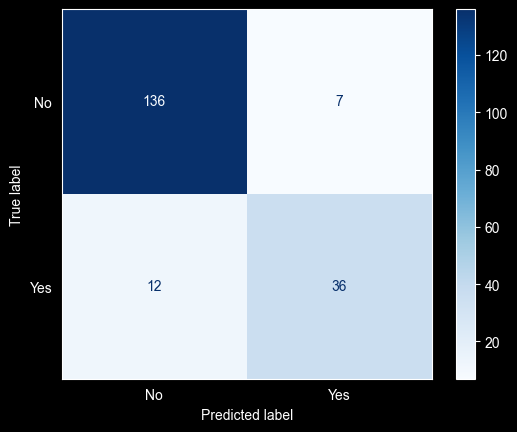

In [126]:
cm_knn = confusion_matrix(y_test,y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn,display_labels=['No','Yes'])
disp.plot(cmap=plt.cm.Blues)
plt.grid()
plt.show()

In [ ]:
cm =confusion_matrix(y_test,y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['No','Yes'])
disp.plot()
plt.grid()
plt.show()

In [128]:
def metrics(y_true,y_pred):
    accuracy = accuracy_score(y_true,y_pred)
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true,y_pred)
    f1 = f1_score(y_true,y_pred)
    return { 'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)}
print(metrics(y_test,y_pred))

{'accuracy': 0.900523560209424, 'precision': 0.8372093023255814, 'recall': 0.75, 'f1': 0.7912087912087912}


In [ ]:
def mmm(y_true,y_pred):
    accuracy = accuracy_score(y_true,y_pred)
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true,y_pred)
    f1 = f1_score(y_true,y_pred)
    return { 'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
             'f1': float(f1)
    }
print(mmm(y_test,y_pred))

**Accuracy** - za 90% pesama smo tacno pogodili da li se imati veliki broj pustanja ili ne

**Precision** - od svih pesama za koje smo predvideli da ce imati veliko broj pustanja, 83.7% zaista ima veliki broj pustanja

**Recall** - od svih pesama koje zaista imaju veliki broj pustanja, mi smo tacno predvideli 75%

**F1 score** - mera koja balansira preciznost i odziv je 79.1%
